# Data Reading

In [121]:
import pandas as pd

def readFile():
     df = pd.read_csv("E:/1_Eathans/Ethans/Data/Airline/Airline1.csv")
     return df


#  Cleaning

# Source,Destination,Route,Total_Stops,Price


In [122]:
def Handel_Missing(df):
    missin_COL = ['Source','Destination','Route','Total_Stops']
    for i in missin_COL:
        Missing = df[i].mode()[0]
        df.fillna({i:Missing},inplace=True)
        
    Missing_Price = df['Price'].mean()
    df.fillna({'Price':Missing_Price},inplace=True)
    return df


# Handle Duplicates


In [123]:
def Handle_Duplicates(df):
    df.drop_duplicates(inplace=True)
    df[df.duplicated()]
    return df


# Handle unever Values

In [124]:


def Replace_Uneve(df):
    df['Destination'] = df['Destination'].replace({"New Delhi":"Delhi"})
    return df




In [125]:


def convertDur_Min(df):
    for i in df.index:
        ColOne = df.loc[i,'Duration'].split()[0]
        ColTwo = df.loc[i,'Duration'].split()[1]
        
        if "h" in ColOne:
            ColOne = int(ColOne.replace("h",""))*60
        elif "m" in ColOne:
            ColOne = int(ColOne.replace("m",""))

        if "h" in ColTwo:
            ColTwo = int(ColTwo.replace("h",""))*60
        elif "m" in ColTwo:
            ColTwo = int(ColTwo.replace("m",""))
        
        df.loc[i,'DurHrs_Mins'] = ColOne + ColTwo
    return df



In [126]:
def DateTimeConverion(df):
    df['Date_of_Journey'] = pd.to_datetime(df['Date_of_Journey'],format='mixed')
    df['D_day'] = df['Date_of_Journey'].dt.day
    df['D_month'] = df['Date_of_Journey'].dt.month
    df['D_year'] = df['Date_of_Journey'].dt.year
    df['D_hours'] = df['Date_of_Journey'].dt.hour
    df['D_minutes'] = df['Date_of_Journey'].dt.minute

    df['Arrival_Time'] = pd.to_datetime(df['Arrival_Time'],format='mixed')
    df['A_day'] = df['Arrival_Time'].dt.day
    df['A_month'] = df['Arrival_Time'].dt.month
    df['A_year'] = df['Arrival_Time'].dt.year
    df['A_hours'] = df['Arrival_Time'].dt.hour
    df['A_minutes'] = df['Arrival_Time'].dt.minute
    return df


In [127]:
def uncessaryCol(df):
    col_Drop = ['ID','Date_of_Journey','Route','Dep_Time',
                'Arrival_Time','Duration','Additional_Info']
    df.drop(col_Drop,axis=1,inplace=True)
    return df


In [128]:
def remove_Outlier(df):
    final_df = pd.DataFrame(columns=list(df.columns))
    Air_Name = df['Airline'].unique()
    for i in Air_Name:
        newDdf = df[df['Airline']==i]
        q1 = newDdf['Price'].quantile(.25)
        q3 = newDdf['Price'].quantile(.75)
        IQR = q3-q1
        lowerLimit = q1-IQR*1.5
        HigherLimit = q3+IQR*1.5

        HigherLimit
        lowerLimit
        Higer_Outliers = newDdf[newDdf['Price']>=HigherLimit].index
        Lower_Outliers = newDdf[newDdf['Price']<=lowerLimit].index
        final_Outliers = Higer_Outliers.append(Lower_Outliers)
        df.drop(final_Outliers,axis=0,inplace=True)
        
    return df


In [129]:
import seaborn as sns
def show_Plot(df):
    sns.boxplot(x=df['Price'],y=df['Airline'])
    plt.show()



In [130]:
def saveCleanedData(df):
    file_Path = "Airtifacts/Clnd_Data/Cleaned_Data.csv"
    df.to_csv(file_Path,index=False)


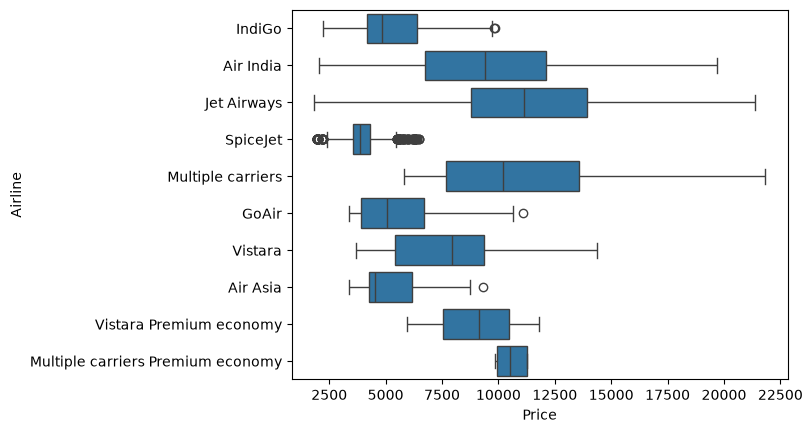

In [131]:
import seaborn as sns
df = readFile()
df = Handel_Missing(df)
df = Handle_Duplicates(df)
df = Replace_Uneve(df)
df = convertDur_Min(df)
df = DateTimeConverion(df)
df = uncessaryCol(df)

df = remove_Outlier(df)
show_Plot(df)
df = saveCleanedData(df)
df
